# Tugas Praktikum Deep Learning — Tugas 1: Customer Churn Prediction (PyTorch)

| | |
|---|---|
| **Nama** | Faiz Farrosian Karim |
| **NRP** | 5054251027 |
| **Framework** | PyTorch |
| **Dataset** | [Churn Modelling](https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling) |

**Tujuan:** memprediksi apakah nasabah bank akan berhenti (*churn*, `Exited = 1`) atau tidak, lalu membandingkan empat model:

1. Logistic Regression (baseline)
2. ANN sederhana (1 hidden layer)
3. ANN lebih dalam dengan Dropout
4. ANN dengan class weight (data imbalanced)

## 1. Import Library & Konfigurasi

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, classification_report)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| device:", device)
sns.set_style("whitegrid")

PyTorch: 2.15.0+cpu | device: cpu


## 2. Load Data & Eksplorasi

In [2]:
import os, glob
# Cari file di folder kerja, Colab (/content), atau Kaggle (/kaggle/input)
cands = glob.glob("Churn_Modelling.csv") + glob.glob("/content/**/Churn_Modelling.csv", recursive=True) + glob.glob("/kaggle/input/**/Churn_Modelling.csv", recursive=True)
assert cands, "Churn_Modelling.csv tidak ditemukan. Upload file ke Colab (panel Files) atau tambahkan dataset di Kaggle."
df = pd.read_csv(cands[0]); print("Memuat:", cands[0])
print(df.shape)
df.head()

Memuat: Churn_Modelling.csv
(10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
df.info()
print("\nMissing values:", df.isna().sum().sum())
print("Duplikat:", df.duplicated().sum())
df.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB

Missing values: 0
Duplikat: 0


,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


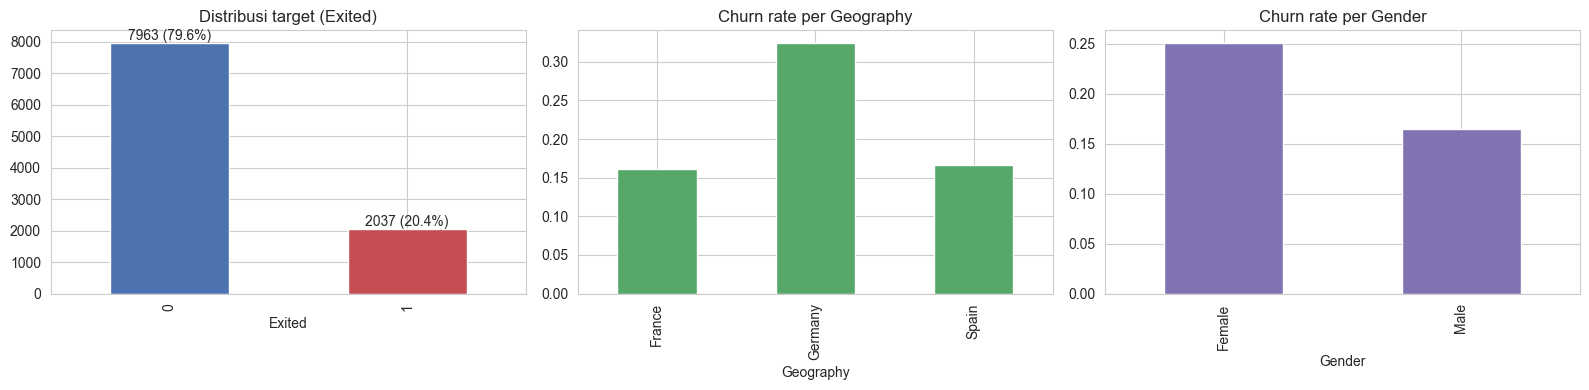

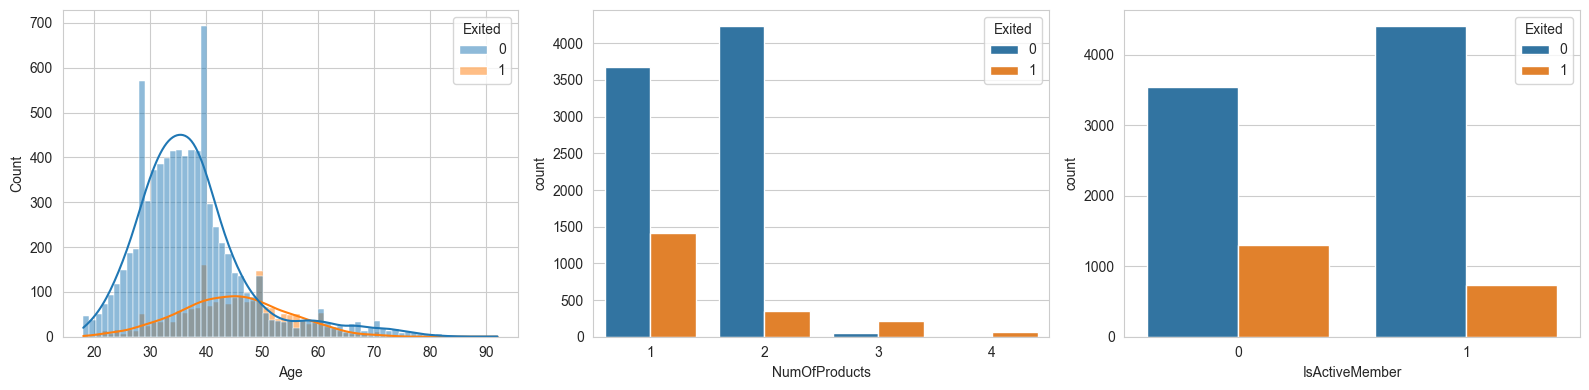

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df["Exited"].value_counts().plot.bar(ax=ax[0], color=["#4C72B0", "#C44E52"]); ax[0].set_title("Distribusi target (Exited)")
for i, v in enumerate(df["Exited"].value_counts()): ax[0].text(i, v, f"{v} ({v/len(df):.1%})", ha="center", va="bottom")
df.groupby("Geography")["Exited"].mean().plot.bar(ax=ax[1], color="#55A868"); ax[1].set_title("Churn rate per Geography")
df.groupby("Gender")["Exited"].mean().plot.bar(ax=ax[2], color="#8172B2"); ax[2].set_title("Churn rate per Gender")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=df, x="Age", hue="Exited", kde=True, ax=ax[0])
sns.countplot(data=df, x="NumOfProducts", hue="Exited", ax=ax[1])
sns.countplot(data=df, x="IsActiveMember", hue="Exited", ax=ax[2])
plt.tight_layout(); plt.show()

**Catatan EDA:** data tidak memiliki missing value dan target **imbalanced** (nasabah churn jauh lebih sedikit dibanding yang bertahan). Karena itu *accuracy* saja tidak cukup untuk menilai model; kita juga memakai Precision, Recall, F1, dan ROC-AUC.

## 3. Preprocessing

- Buang kolom identitas yang tidak informatif: `RowNumber`, `CustomerId`, `Surname`.
- Fitur kategorikal (`Geography`, `Gender`) → one-hot encoding (`drop_first=True`).
- Split **stratified** 70% train / 15% validation / 15% test.
- Standarisasi fitur numerik (*scaler di-fit hanya pada data train* agar tidak terjadi data leakage).

In [5]:
data = df.drop(columns=["RowNumber", "CustomerId", "Surname"])
data = pd.get_dummies(data, columns=["Geography", "Gender"], drop_first=True, dtype=int)
X = data.drop(columns="Exited"); y = data["Exited"].values
feature_names = X.columns.tolist(); print(feature_names)

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

scaler = StandardScaler().fit(X_train)
X_train, X_val, X_test = [scaler.transform(a).astype("float32") for a in (X_train, X_val, X_test)]
print("Train/Val/Test:", X_train.shape, X_val.shape, X_test.shape)
print("Churn rate train/val/test:", y_train.mean().round(3), y_val.mean().round(3), y_test.mean().round(3))

def make_loader(X, y, bs=64, shuffle=False):
    ds = TensorDataset(torch.tensor(X), torch.tensor(y, dtype=torch.float32))
    return DataLoader(ds, batch_size=bs, shuffle=shuffle)
train_loader = make_loader(X_train, y_train, shuffle=True)
val_loader   = make_loader(X_val, y_val, bs=512)
test_loader  = make_loader(X_test, y_test, bs=512)
n_features = X_train.shape[1]

['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']
Train/Val/Test: (7000, 11) (1500, 11) (1500, 11)
Churn rate train/val/test: 0.204 0.204 0.203


## 4. Fungsi Bantu (Training, Evaluasi, Learning Curve)

Semua model menghasilkan **logit** (1 output) dan dilatih dengan `BCEWithLogitsLoss`. Training memakai optimizer Adam; bobot terbaik (val loss terendah) disimpan lalu dipulihkan di akhir training. Untuk model dengan class weight, `pos_weight` dipasang pada loss.

In [6]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb).squeeze(1)
            loss = criterion(logits, yb)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total += loss.item() * len(xb)
            correct += ((logits > 0).float() == yb).sum().item(); n += len(xb)
    return total / n, correct / n

def fit(model, epochs=60, lr=1e-3, pos_weight=None, weight_decay=0.0, name="model"):
    model.to(device)
    pw = None if pos_weight is None else torch.tensor([pos_weight], device=device)
    # Loss validasi/training memakai kriteria yang sama agar learning curve konsisten
    criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    hist = {"loss": [], "val_loss": [], "acc": [], "val_acc": []}
    best, best_state = float("inf"), None
    for ep in range(epochs):
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(hist, (tl, vl, ta, va)): hist[k].append(v)
        if vl < best: best, best_state = vl, {k: v.clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    print(f"[{name}] best val_loss={best:.4f} @ epoch {int(np.argmin(hist['val_loss']))+1}")
    return hist

def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4)); ep = range(1, len(hist["loss"]) + 1)
    ax[0].plot(ep, hist["loss"], label="train"); ax[0].plot(ep, hist["val_loss"], label="validation")
    ax[0].set(title=f"{title} — Loss", xlabel="Epoch", ylabel="Loss"); ax[0].legend()
    ax[1].plot(ep, hist["acc"], label="train"); ax[1].plot(ep, hist["val_acc"], label="validation")
    ax[1].set(title=f"{title} — Accuracy", xlabel="Epoch", ylabel="Accuracy"); ax[1].legend()
    plt.tight_layout(); plt.show()

@torch.no_grad()
def predict_proba(model, X):
    model.eval()
    return torch.sigmoid(model(torch.tensor(X).to(device)).squeeze(1)).cpu().numpy()

results, probas = {}, {}
def evaluate(model, name, threshold=0.5):
    p = predict_proba(model, X_test); pred = (p >= threshold).astype(int); probas[name] = p
    results[name] = {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred, zero_division=0),
                     "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, p)}
    print(classification_report(y_test, pred, target_names=["Stay (0)", "Churn (1)"], digits=3))
    cm = confusion_matrix(y_test, pred)
    plt.figure(figsize=(4, 3.4)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=["Stay", "Churn"], yticklabels=["Stay", "Churn"]); plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Prediksi"); plt.ylabel("Aktual"); plt.show()

## 5. Model 1 — Logistic Regression (Baseline)

Logistic Regression setara dengan jaringan **tanpa hidden layer**: satu layer linear + sigmoid.

[LogReg] best val_loss=0.4165 @ epoch 44


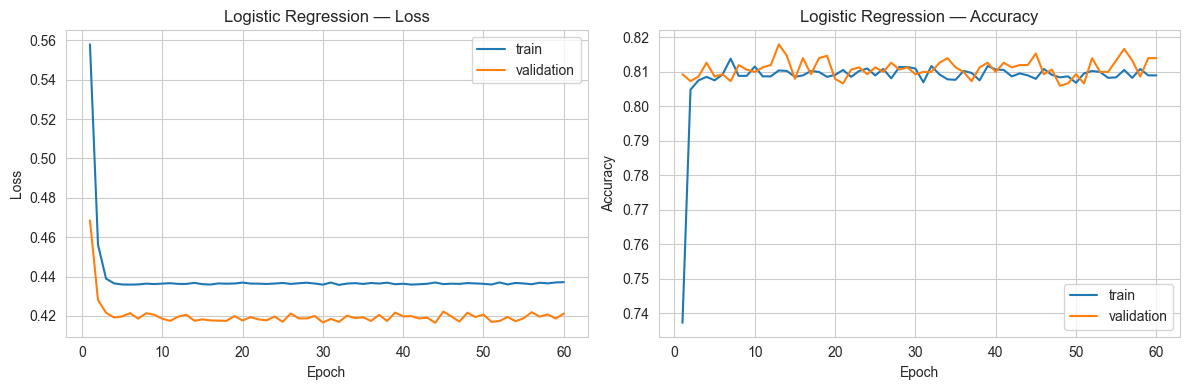

              precision    recall  f1-score   support

    Stay (0)      0.827     0.973     0.894      1195
   Churn (1)      0.660     0.203     0.311       305

    accuracy                          0.817      1500
   macro avg      0.743     0.588     0.603      1500
weighted avg      0.793     0.817     0.776      1500



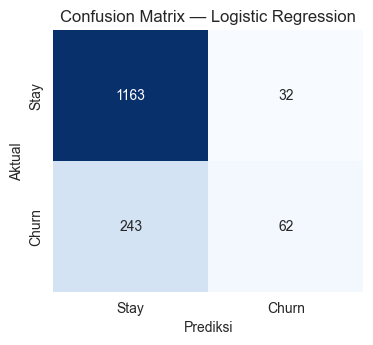

In [7]:
torch.manual_seed(SEED)
logreg = nn.Linear(n_features, 1)
h1 = fit(logreg, epochs=60, lr=1e-2, name="LogReg")
plot_history(h1, "Logistic Regression")
evaluate(logreg, "Logistic Regression")

## 6. Model 2 — ANN Sederhana (1 Hidden Layer)

Sequential(
  (0): Linear(in_features=11, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)
[ANN Simple] best val_loss=0.3287 @ epoch 59


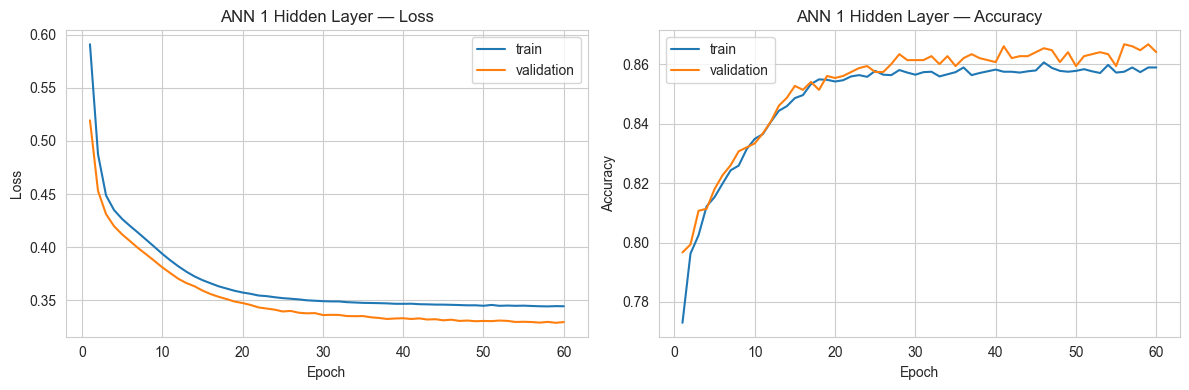

              precision    recall  f1-score   support

    Stay (0)      0.879     0.971     0.922      1195
   Churn (1)      0.806     0.475     0.598       305

    accuracy                          0.870      1500
   macro avg      0.842     0.723     0.760      1500
weighted avg      0.864     0.870     0.856      1500



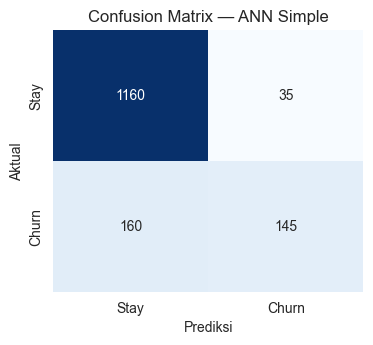

In [8]:
torch.manual_seed(SEED)
ann_simple = nn.Sequential(nn.Linear(n_features, 16), nn.ReLU(), nn.Linear(16, 1))
print(ann_simple)
h2 = fit(ann_simple, epochs=60, lr=1e-3, name="ANN Simple")
plot_history(h2, "ANN 1 Hidden Layer")
evaluate(ann_simple, "ANN Simple")

## 7. Model 3 — ANN Lebih Dalam dengan Dropout

Sequential(
  (0): Linear(in_features=11, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=64, out_features=32, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=32, out_features=16, bias=True)
  (7): ReLU()
  (8): Dropout(p=0.2, inplace=False)
  (9): Linear(in_features=16, out_features=1, bias=True)
)
[ANN Deep+Dropout] best val_loss=0.3189 @ epoch 45


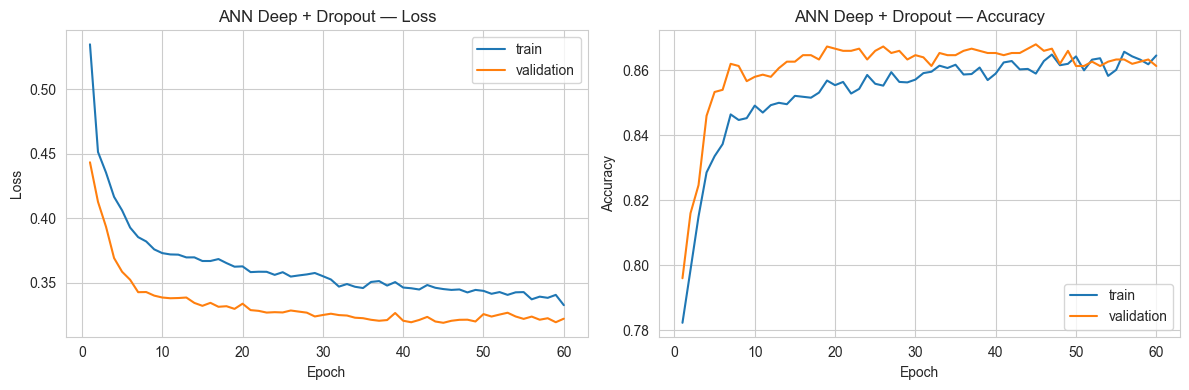

              precision    recall  f1-score   support

    Stay (0)      0.879     0.966     0.920      1195
   Churn (1)      0.781     0.479     0.593       305

    accuracy                          0.867      1500
   macro avg      0.830     0.722     0.757      1500
weighted avg      0.859     0.867     0.854      1500



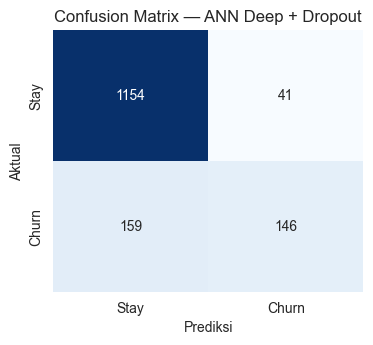

In [9]:
torch.manual_seed(SEED)
ann_deep = nn.Sequential(
    nn.Linear(n_features, 64), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(32, 16), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(16, 1))
print(ann_deep)
h3 = fit(ann_deep, epochs=60, lr=1e-3, name="ANN Deep+Dropout")
plot_history(h3, "ANN Deep + Dropout")
evaluate(ann_deep, "ANN Deep + Dropout")

## 8. Model 4 — ANN dengan Class Weight

Pada data imbalanced, loss standar didominasi kelas mayoritas. Kita beri bobot lebih besar pada kelas *churn* melalui `pos_weight = jumlah negatif / jumlah positif` pada data train. Arsitektur sama dengan Model 3 agar perbandingan adil.

pos_weight = 3.909
[ANN ClassWeight] best val_loss=0.6982 @ epoch 60


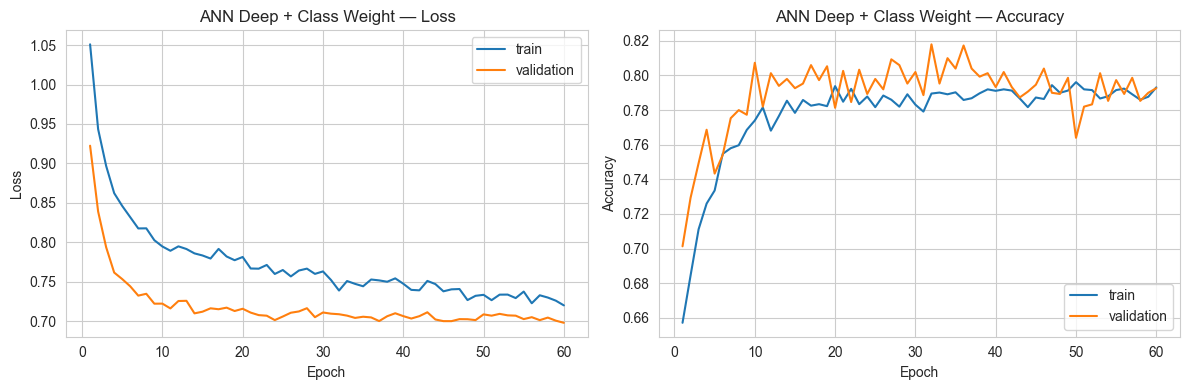

              precision    recall  f1-score   support

    Stay (0)      0.926     0.795     0.855      1195
   Churn (1)      0.483     0.751     0.588       305

    accuracy                          0.786      1500
   macro avg      0.705     0.773     0.722      1500
weighted avg      0.836     0.786     0.801      1500



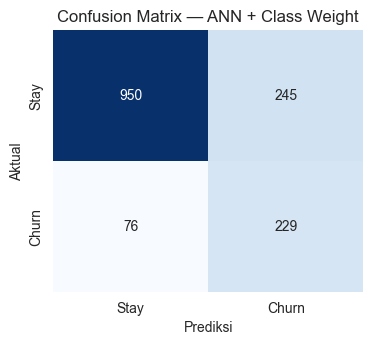

In [10]:
pos_w = (y_train == 0).sum() / (y_train == 1).sum()
print(f"pos_weight = {pos_w:.3f}")
torch.manual_seed(SEED)
ann_cw = nn.Sequential(
    nn.Linear(n_features, 64), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(64, 32), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(32, 16), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(16, 1))
h4 = fit(ann_cw, epochs=60, lr=1e-3, pos_weight=float(pos_w), name="ANN ClassWeight")
plot_history(h4, "ANN Deep + Class Weight")
evaluate(ann_cw, "ANN + Class Weight")

> **Catatan:** pada model dengan class weight, *loss* yang ditampilkan sudah terboboti sehingga skalanya tidak bisa dibandingkan langsung dengan model lain, dan *accuracy* training/validasi turun karena model sengaja lebih sering memprediksi *churn*.

## 9. Perbandingan Seluruh Model

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.8167,0.6596,0.2033,0.3108,0.7891
ANN Simple,0.8700,0.8056,0.4754,0.5979,0.8617
ANN Deep + Dropout,0.8667,0.7807,0.4787,0.5935,0.8649
ANN + Class Weight,0.7860,0.4831,0.7508,0.5879,0.8622


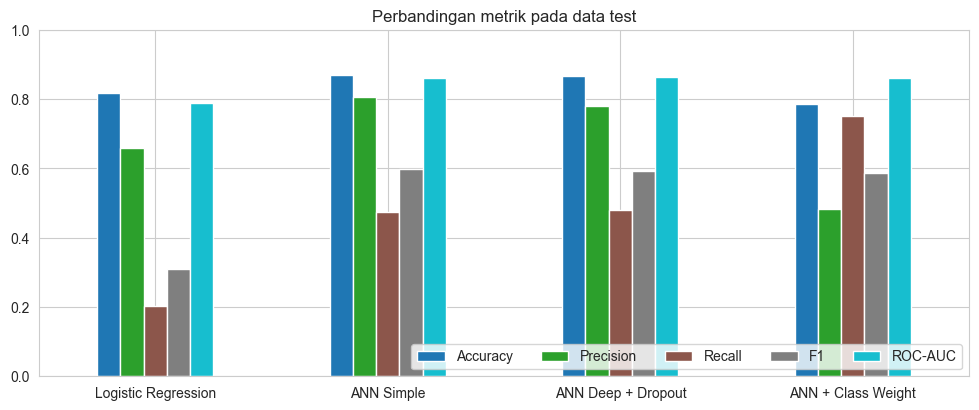

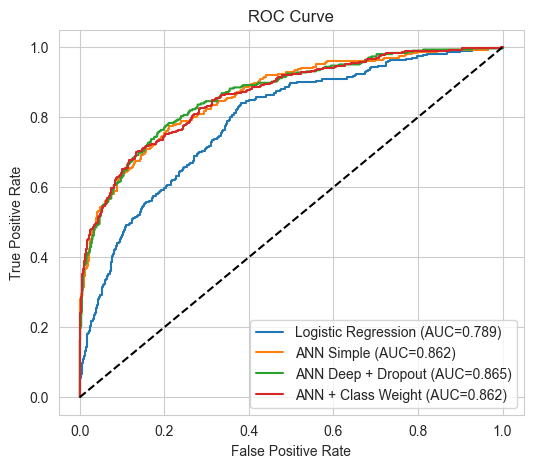

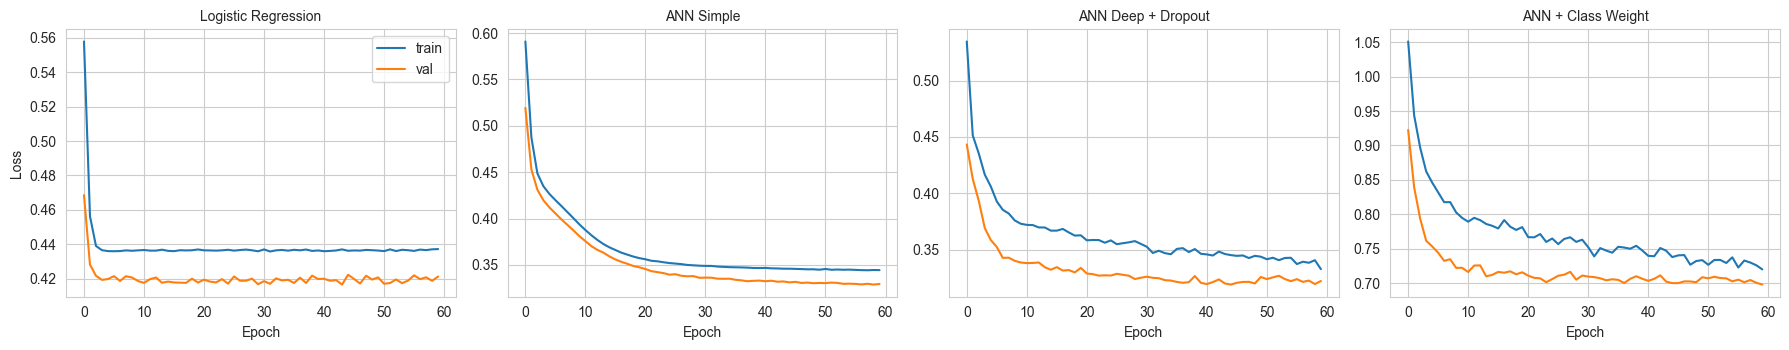

In [11]:
res = pd.DataFrame(results).T.round(4)
display(res.style.background_gradient(cmap="Greens", axis=0).format("{:.4f}"))

res.plot.bar(figsize=(12, 4.5), rot=0, colormap="tab10"); plt.title("Perbandingan metrik pada data test")
plt.ylim(0, 1); plt.legend(loc="lower right", ncol=5); plt.show()

plt.figure(figsize=(6, 5))
for n, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p); plt.plot(fpr, tpr, label=f"{n} (AUC={results[n]['ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], "k--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve"); plt.legend(); plt.show()

hists = {"Logistic Regression": h1, "ANN Simple": h2, "ANN Deep + Dropout": h3, "ANN + Class Weight": h4}
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6), sharey=False)
for a, (n, h) in zip(ax, hists.items()):
    a.plot(h["loss"], label="train"); a.plot(h["val_loss"], label="val"); a.set_title(n, fontsize=10); a.set_xlabel("Epoch")
ax[0].set_ylabel("Loss"); ax[0].legend(); plt.tight_layout(); plt.show()

## 10. Analisis & Kesimpulan

### a. Tabel hasil

Metrik berikut merupakan hasil evaluasi pada **data test** sebanyak 1.500 data. Precision, Recall, dan F1 yang ditampilkan mengacu pada kelas **Churn (Exited = 1)**.

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | 0.8167 | 0.6596 | 0.2033 | 0.3108 | 0.7891 |
| ANN 1 hidden layer | 0.8700 | 0.8056 | 0.4754 | 0.5979 | 0.8617 |
| ANN Deep + Dropout | 0.8667 | 0.7807 | 0.4787 | 0.5935 | 0.8649 |
| ANN + Class Weight | 0.7860 | 0.4831 | 0.7508 | 0.5879 | 0.8622 |

### b. Analisis learning curve

- **Logistic Regression:** Loss training dan validation turun tajam pada epoch awal, kemudian relatif mendatar. Nilai validation loss terendah tercatat pada **epoch 44 (0.4165)**. Tidak terlihat pola validation loss yang terus meningkat ketika training loss menurun, sehingga tidak ada indikasi overfitting yang kuat. Namun, kurva yang cepat mendatar menunjukkan kemampuan model baseline ini terbatas dalam mempelajari pola yang lebih kompleks.
- **ANN 1 hidden layer:** Kedua loss turun secara bertahap dan tetap berdekatan. Validation loss terendah tercatat pada **epoch 59 (0.3287)**. Validation loss yang tidak meningkat saat training loss menurun menunjukkan tidak ada indikasi overfitting yang jelas pada kurva ini. Model masih menunjukkan perbaikan hingga mendekati akhir pelatihan.
- **ANN Deep + Dropout:** Training loss dan validation loss sama-sama menurun. Validation loss terendah tercatat pada **epoch 45 (0.3189)**. Validation loss cenderung lebih rendah daripada training loss; hal ini dapat terjadi karena Dropout aktif saat training sehingga proses belajar lebih menantang, sedangkan Dropout tidak aktif saat evaluasi. Tidak tampak kenaikan validation loss yang berkelanjutan, sehingga tidak terlihat overfitting yang kuat.
- **ANN + Class Weight:** Kedua loss menurun, dengan validation loss terendah **0.6982 pada epoch 60**. Kurva tidak memperlihatkan validation loss yang terus meningkat. Akan tetapi, nilai loss model ini sudah menggunakan class weight, sehingga skalanya tidak dapat dibandingkan langsung dengan loss model lain.

Secara umum, tidak terlihat gejala overfitting yang kuat pada keempat kurva. Dibandingkan ANN sederhana, model Deep + Dropout memiliki kurva training dan validation loss yang relatif stabil serta berdekatan. Meski demikian, hasil ini tidak berarti Dropout selalu menghasilkan metrik test yang lebih baik: ANN sederhana masih sedikit unggul pada Accuracy, Precision, dan F1, sedangkan ANN Deep + Dropout unggul tipis pada Recall dan ROC-AUC.

### c. Analisis metrik dan imbalanced data

Dataset memiliki **7.963 data nasabah yang tidak churn (79,63%)** dan **2.037 data nasabah yang churn (20,37%)**. Karena kelas mayoritas adalah nasabah yang tidak churn, model yang selalu memprediksi semua nasabah tidak churn pun secara teoritis dapat memperoleh Accuracy sebesar 79,63%, tetapi gagal mendeteksi nasabah churn. Oleh karena itu, Accuracy saja tidak cukup untuk menilai keberhasilan model.

Logistic Regression memperoleh Accuracy 81,67%, tetapi Recall kelas churn hanya 20,33%. Artinya, model hanya berhasil menemukan sebagian kecil dari seluruh nasabah yang benar-benar churn. ANN sederhana dan ANN Deep + Dropout meningkatkan Recall menjadi masing-masing 47,54% dan 47,87%, dengan Precision yang juga lebih tinggi daripada baseline.

Penggunaan **class weight** memberikan perubahan yang jelas. Dibandingkan ANN Deep + Dropout, ANN + Class Weight meningkatkan Recall dari **47,87% menjadi 75,08%**. Dengan demikian, model berbobot kelas berhasil menangkap lebih banyak nasabah yang benar-benar churn. Namun, Precision turun dari **78,07% menjadi 48,31%**. Artinya, prediksi churn dari model ini lebih sering keliru; bank perlu menindaklanjuti lebih banyak nasabah yang sebenarnya tidak churn. Accuracy juga turun dari 86,67% menjadi 78,60%.

Trade-off tersebut menunjukkan bahwa class weight menggeser kecenderungan model agar lebih peka terhadap kelas minoritas. Model ini cocok ketika kehilangan kesempatan mendeteksi nasabah yang berpotensi churn dianggap lebih merugikan daripada melakukan pemeriksaan lanjutan terhadap nasabah yang ternyata tidak churn. Sebaliknya, jika biaya tindak lanjut atau risiko salah sasaran tinggi, Precision perlu lebih diprioritaskan.

Model ANN yang lebih kompleks tidak otomatis lebih baik pada semua metrik. ANN sederhana menghasilkan Accuracy (87,00%), Precision (80,56%), dan F1 (0,5979) tertinggi. ANN Deep + Dropout memiliki ROC-AUC tertinggi (0,8649) dan Recall sedikit lebih tinggi daripada ANN sederhana (47,87% dibanding 47,54%). Perbedaan metrik keduanya relatif kecil. Keduanya jauh lebih baik daripada Logistic Regression pada sebagian besar metrik, tetapi model yang lebih dalam belum menunjukkan peningkatan menyeluruh dibanding ANN sederhana. Dengan demikian, kompleksitas arsitektur saja tidak menjamin kinerja yang lebih baik.

### d. Kesimpulan

Berdasarkan hasil pengujian, **ANN 1 hidden layer merupakan pilihan terbaik apabila tujuan utama adalah memperoleh keseimbangan kinerja klasifikasi pada threshold 0,5**, karena model ini menghasilkan Accuracy, Precision, dan F1 tertinggi, masing-masing sebesar 87,00%, 80,56%, dan 0,5979. Sementara itu, apabila bank lebih mengutamakan kemampuan menemukan sebanyak mungkin nasabah yang berpotensi churn, **ANN + Class Weight lebih sesuai**, karena Recall kelas churn mencapai 75,08%, tertinggi di antara seluruh model. Pilihan model terbaik bergantung pada tujuan operasional bank, bukan hanya satu nilai metrik.

Untuk penerapan di bank, mendeteksi nasabah yang berpotensi churn sebanyak mungkin dapat menjadi prioritas awal agar bank memiliki kesempatan melakukan pendekatan atau menawarkan program retensi. Oleh sebab itu, Recall penting diperhatikan. Namun, Precision juga harus dipertimbangkan agar sumber daya bank tidak terlalu banyak digunakan untuk menindaklanjuti nasabah yang sebenarnya tidak akan churn. Hasil prediksi sebaiknya digunakan sebagai dasar penentuan prioritas tindak lanjut, bukan sebagai keputusan otomatis terhadap nasabah.

Beberapa pengembangan yang dapat dilakukan adalah:
1. **Threshold tuning:** mencari ambang probabilitas selain 0,5 untuk memperoleh keseimbangan Precision dan Recall yang sesuai dengan kebutuhan bank. Pemilihan threshold sebaiknya dilakukan menggunakan data validation, kemudian dievaluasi sekali pada data test.
2. **Penanganan ketidakseimbangan kelas:** membandingkan class weight dengan metode seperti SMOTE yang diterapkan hanya pada data training agar tidak terjadi kebocoran data.
3. **Hyperparameter tuning:** mencoba variasi jumlah neuron, jumlah hidden layer, learning rate, batch size, dropout, dan weight decay.
4. **Evaluasi berdasarkan kebutuhan bisnis:** mempertimbangkan biaya kehilangan nasabah dan biaya tindak lanjut yang salah sasaran, serta memeriksa confusion matrix dan kurva Precision-Recall.

Secara keseluruhan, eksperimen menunjukkan bahwa ANN memberikan peningkatan kinerja dibanding Logistic Regression pada dataset ini. Class weight terbukti meningkatkan kemampuan mendeteksi kelas churn, tetapi peningkatan Recall tersebut disertai penurunan Precision dan Accuracy. Oleh karena itu, pemilihan model akhir perlu disesuaikan dengan prioritas bank dalam mengelola risiko churn.
